Fundação Getulio Vargas

Escola de Relações Internacionais

Ciência de Dados em Ambientes de Negócios, 2026.2

Professora Walkiria Resende

Alunas: Allegra Scheffer, Maria Isadora Camargo (C368703) e Maria Luisa


Importando bibliotecas

In [ ]:
!pip install ucimlrepo

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import zipfile
import io
import urllib.request

Imprtando a base "Bank Marketing" da UCI

In [ ]:
url = "https://archive.ics.uci.edu/ml/machine-learning-databases/00222/bank-additional.zip"

resposta = urllib.request.urlopen(url)
arquivo_zip = zipfile.ZipFile(io.BytesIO(resposta.read()))

with arquivo_zip.open("bank-additional/bank-additional-full.csv") as arquivo:
    df = pd.read_csv(arquivo, sep=";")

print("Dimensões da base:", df.shape)
display(df.head())

Dimensões da base: (41188, 21)


,age,job,marital,education,default,housing,loan,contact,month,day_of_week,...,campaign,pdays,previous,poutcome,emp.var.rate,cons.price.idx,cons.conf.idx,euribor3m,nr.employed,y
0,56,housemaid,married,basic.4y,no,no,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
1,57,services,married,high.school,unknown,no,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
2,37,services,married,high.school,no,yes,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
3,40,admin.,married,basic.6y,no,no,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
4,56,services,married,high.school,no,no,yes,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no


In [ ]:
#A base de dados indica NANs como "unknown". Dessa forma, substituímos "unknown" por NaN em todo o dataset:
df = df.replace("unknown", np.nan)

# Perfilamento das colunas
perfil = pd.DataFrame({
    "tipo": df.dtypes.astype(str),
    "nulos": df.isna().sum(),
    "nulos_%": (df.isna().mean() * 100).round(2),
    "n_unicos": df.nunique()
})

display(perfil)

# Verificação de duplicatas
print("Linhas duplicadas:", df.duplicated().sum())

# Distribuição da variável-alvo
print("\nDistribuição do alvo:")
print(df["y"].value_counts())

print("\nDistribuição percentual do alvo:")
print((df["y"].value_counts(normalize=True) * 100).round(2))

,tipo,nulos,nulos_%,n_unicos
age,int64,0,0.00,78
job,object,330,0.80,11
marital,object,80,0.19,3
education,object,1731,4.20,7
default,object,8597,20.87,2
housing,object,990,2.40,2
loan,object,990,2.40,2
contact,object,0,0.00,2
month,object,0,0.00,10
day_of_week,object,0,0.00,5


Linhas duplicadas: 12

Distribuição do alvo:
y
no     36548
yes     4640
Name: count, dtype: int64

Distribuição percentual do alvo:
y
no     88.73
yes    11.27
Name: proportion, dtype: float64


In [ ]:
#Existem 12 linhas duplicadas, para ver quais são:
duplicadas = df[df.duplicated(keep=False)]

display(duplicadas)

,age,job,marital,education,default,housing,loan,contact,month,day_of_week,...,campaign,pdays,previous,poutcome,emp.var.rate,cons.price.idx,cons.conf.idx,euribor3m,nr.employed,y
1265,39,blue-collar,married,basic.6y,no,no,no,telephone,may,thu,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.855,5191.0,no
1266,39,blue-collar,married,basic.6y,no,no,no,telephone,may,thu,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.855,5191.0,no
12260,36,retired,married,NaN,no,no,no,telephone,jul,thu,...,1,999,0,nonexistent,1.4,93.918,-42.7,4.966,5228.1,no
12261,36,retired,married,NaN,no,no,no,telephone,jul,thu,...,1,999,0,nonexistent,1.4,93.918,-42.7,4.966,5228.1,no
14155,27,technician,single,professional.course,no,no,no,cellular,jul,mon,...,2,999,0,nonexistent,1.4,93.918,-42.7,4.962,5228.1,no
14234,27,technician,single,professional.course,no,no,no,cellular,jul,mon,...,2,999,0,nonexistent,1.4,93.918,-42.7,4.962,5228.1,no
16819,47,technician,divorced,high.school,no,yes,no,cellular,jul,thu,...,3,999,0,nonexistent,1.4,93.918,-42.7,4.962,5228.1,no
16956,47,technician,divorced,high.school,no,yes,no,cellular,jul,thu,...,3,999,0,nonexistent,1.4,93.918,-42.7,4.962,5228.1,no
18464,32,technician,single,professional.course,no,yes,no,cellular,jul,thu,...,1,999,0,nonexistent,1.4,93.918,-42.7,4.968,5228.1,no
18465,32,technician,single,professional.course,no,yes,no,cellular,jul,thu,...,1,999,0,nonexistent,1.4,93.918,-42.7,4.968,5228.1,no


Taxa geral de adesão: 11.27%


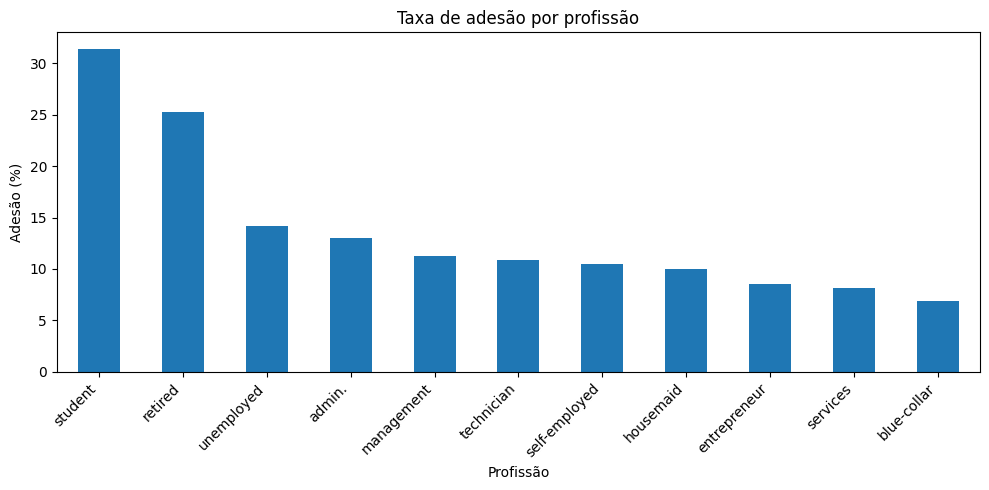

In [ ]:
# Taxa geral de adesão
taxa_adesao = (df["y"] == "yes").mean() * 100
print(f"Taxa geral de adesão: {taxa_adesao:.2f}%")

# Taxa de adesão por profissão
adesao_profissao = (
    df.assign(aderiu=df["y"].eq("yes"))
    .groupby("job")["aderiu"]
    .mean()
    .mul(100)
    .sort_values(ascending=False)
)

adesao_profissao.plot(kind="bar", figsize=(10, 5))
plt.title("Taxa de adesão por profissão")
plt.ylabel("Adesão (%)")
plt.xlabel("Profissão")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

In [ ]:
#Para identificar se existem valores não compatíveis com a categoria:
numericas = df.select_dtypes(include="number")

display(numericas.describe().T)

# Idades iguais ou inferiores a zero
print("Idades inválidas:",
      (df["age"] <= 0).sum())

# Número de contatos na campanha atual
print("Campaign abaixo de 1:",
      (df["campaign"] < 1).sum())

# Valores negativos em variáveis que representam contagens
for coluna in ["age", "campaign", "previous"]:
    print(
        coluna,
        "negativos:",
        (df[coluna] < 0).sum()
    )

,count,mean,std,min,25%,50%,75%,max
age,41188.0,40.024060,10.421250,17.000,32.000,38.000,47.000,98.000
duration,41188.0,258.285010,259.279249,0.000,102.000,180.000,319.000,4918.000
campaign,41188.0,2.567593,2.770014,1.000,1.000,2.000,3.000,56.000
pdays,41188.0,962.475454,186.910907,0.000,999.000,999.000,999.000,999.000
previous,41188.0,0.172963,0.494901,0.000,0.000,0.000,0.000,7.000
emp.var.rate,41188.0,0.081886,1.570960,-3.400,-1.800,1.100,1.400,1.400
cons.price.idx,41188.0,93.575664,0.578840,92.201,93.075,93.749,93.994,94.767
cons.conf.idx,41188.0,-40.502600,4.628198,-50.800,-42.700,-41.800,-36.400,-26.900
euribor3m,41188.0,3.621291,1.734447,0.634,1.344,4.857,4.961,5.045
nr.employed,41188.0,5167.035911,72.251528,4963.600,5099.100,5191.000,5228.100,5228.100


Idades inválidas: 0
Campaign abaixo de 1: 0
age negativos: 0
campaign negativos: 0
previous negativos: 0


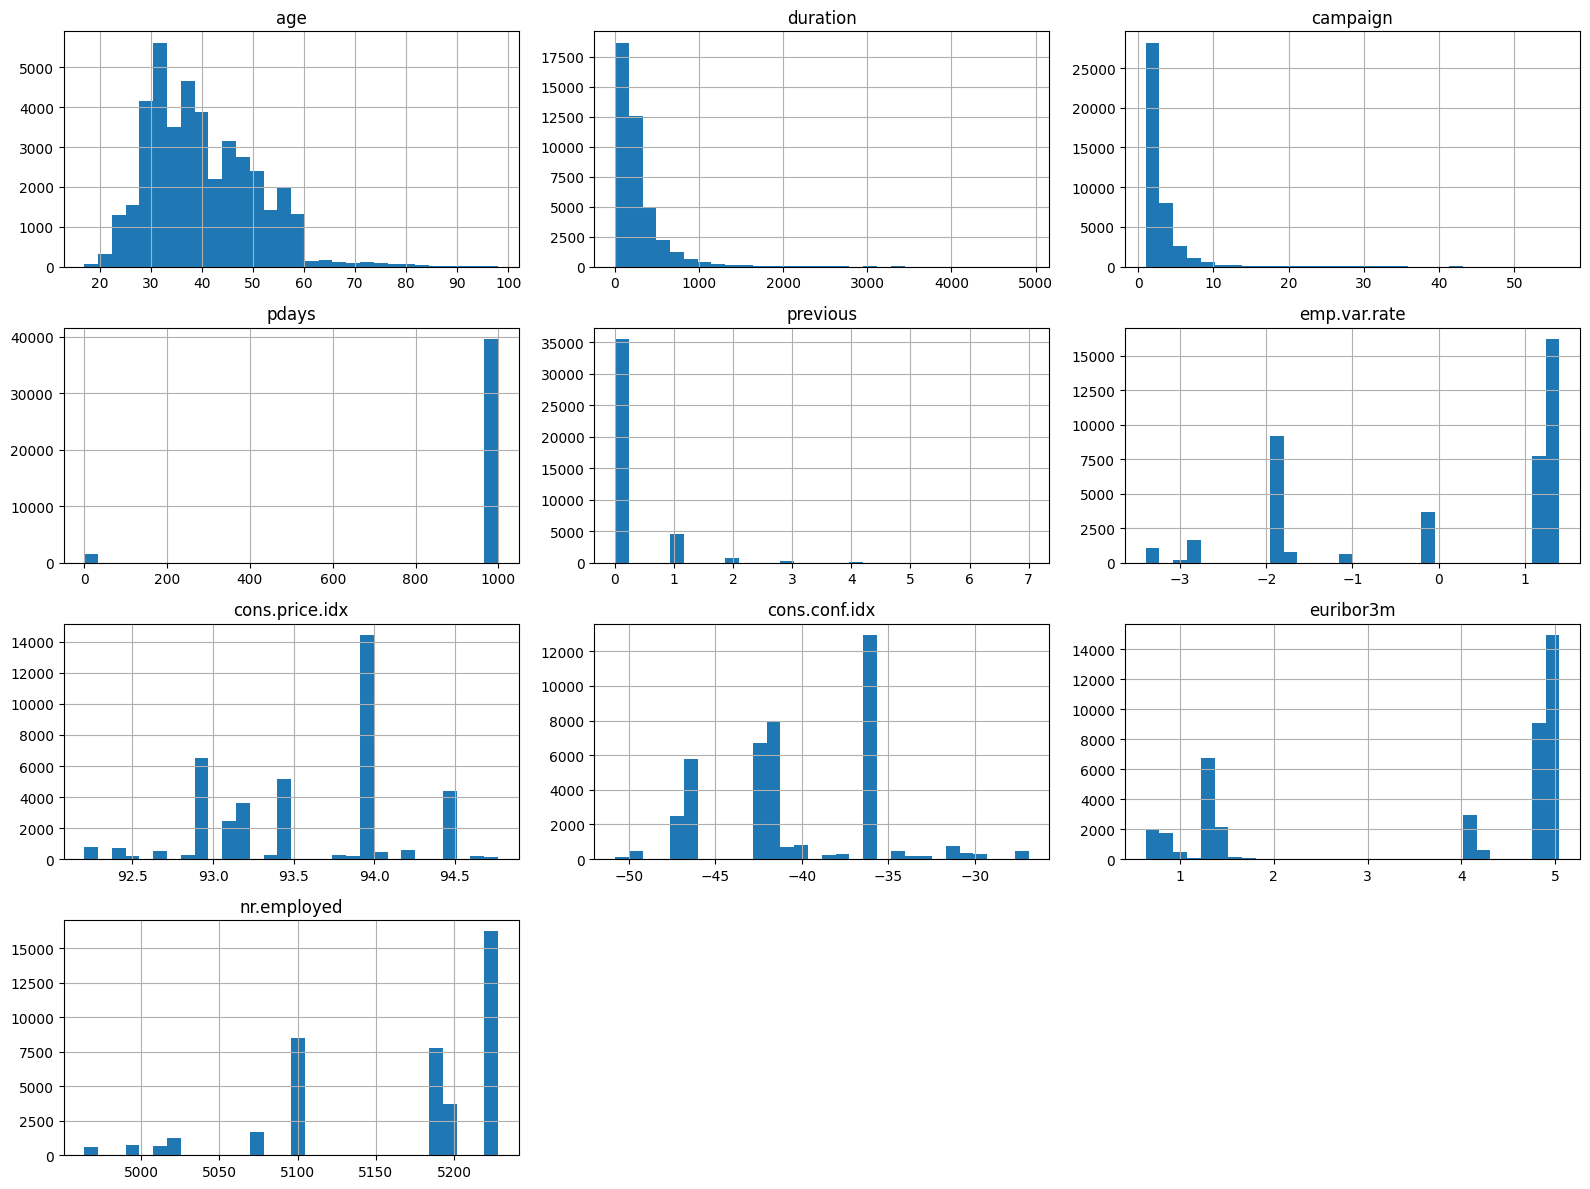

In [ ]:
#Distribuição das variáveis numéricas:

df.hist(figsize=(16, 12), bins=30)
plt.tight_layout()
plt.show()